## Assignment IV: Interpolation, Extrapolation, and Root Finding

**Total: 50 points + 10 bonus points.** Questions 1 and 2 are 25 points each. The Bonus question is worth 10 extra points.

This assignment pulls together the material on interpolation with `scipy.interpolate` (1-D interpolation and **extrapolation**) and root finding with `scipy.optimize.root_scalar`. The Bonus question combines the two.

- Each question is split into **Part (a)** and **Part (b)**.
- Write your code in the cell provided for each part. Make sure it **prints** your numerical answers clearly (ideally with an f-string that says what the printed value represents) and **shows** every requested figure.
- Some parts ask a written question. Answer those in the **markdown cell** provided right below the code cell.
- **Before you submit, make sure that all outputs and all plots are visible in the notebook.** Run every cell; printed answers or figures that do not appear in the submitted notebook cannot be graded.
- Every figure must have axis labels and a title. Panels that show more than one curve need a legend.
- **Submission:** see the instructions at the very end of this notebook.

### AI Usage Policy

**No AI tools (ChatGPT, Claude, GitHub Copilot's suggestion/chat features, etc.) may be used to generate, complete, or rewrite your solutions for this assignment.** All code and explanations must be your own work.

**Exception and disclosure requirement:** If you have **GitHub Copilot active** in your editor (e.g. inline autocomplete suggestions appearing as you type), you do not need to disable it, but you **must disclose this** by adding a short **markdown cell right below this one** stating:
- That Copilot (or any other AI tool) was active while you worked, and
- Briefly, how you used or did not use its suggestions (e.g. "Copilot was active but I did not accept any of its suggestions for graded cells" or "I accepted a Copilot suggestion for the `ax.set_xlabel` lines in Q2(a) but wrote the rest myself").

Notebooks with AI-generated solutions that are not disclosed as above will not receive credit, regardless of correctness.

**AI Usage Disclosure (student to fill in):**

No AI was used during assignment.

Run this cell first (do not change it).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.interpolate as si
from scipy.optimize import root_scalar

### Question 1: Charging Your Phone (25 points)

You plug in your phone at 15 % and write down the battery level every few minutes. The phone only shows **whole percents**:

| time $t$ (min) | 0 | 5 | 10 | 20 | 30 | 40 | 50 |
|---|---|---|---|---|---|---|---|
| battery $B$ (%) | 15 | 30 | 43 | 62 | 74 | 83 | 88 |

Charging slows down as the battery fills up. A simple model for this charger is
$$
B(t) = 100 - 85\,e^{-0.04\,t},
$$
which approaches 100 % but never passes it. **Use the model only to check your answers**, never to build the interpolants.

Run the cell below to define the data and the model (do not change it).

In [2]:
t = np.array([0, 5, 10, 20, 30, 40, 50.])      # minutes since plugging in
B = np.array([15, 30, 43, 62, 74, 83, 88.])     # battery level in %

def battery_model(t):
    """the charging model, only for checking"""
    return 100 - 85 * np.exp(-0.04 * t)

**(a) [10 pts] Interpolate.**
1. Build four interpolants of the data: cubic spline, PCHIP, Akima and Makima. For Akima and Makima pass `extrapolate=True` (you will need it in part (b)).
2. Plot all four on `tn = np.linspace(0, 50, 201)` in one figure, together with the data points.
3. Print each method's estimate of the battery level at $t = 25$ minutes, and the model value.

In the markdown cell below: do the four methods agree between the measurements?

interpolation method cubic spline at 25 minutes: 68.57317073170731
interpolation method PCHIP at 25 minutes: 68.55299539170507
interpolation method Akima at 25 minutes: 68.50113636363636
interpolation method Makima at 25 minutes: 68.52657497396739


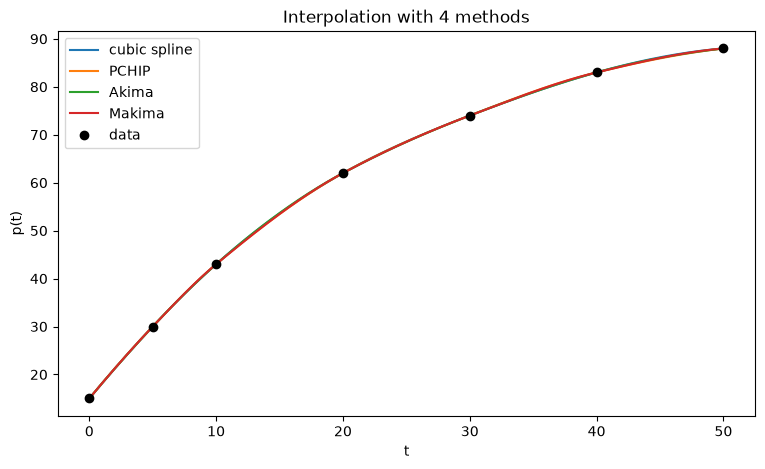

In [60]:
names = ["cubic spline", "PCHIP", "Akima", "Makima"]
methods = [si.CubicSpline(t, B),
           si.PchipInterpolator(t, B),
           si.Akima1DInterpolator(t, B, extrapolate=True),
           si.Akima1DInterpolator(t, B, method="makima", extrapolate=True)]

tn = np.linspace(0, 50, 201)

fig, ax = plt.subplots(figsize=(9, 5))
for name, p in zip(names, methods):
    ax.plot(tn, p(tn), label=name)
    print(f"interpolation method {name} at 25 minutes: {p(25)}")
ax.plot(t, B, "ko", label="data")
ax.set_xlabel("t"); ax.set_ylabel("p(t)")
ax.legend()
ax.set_title("Interpolation with 4 methods")
plt.show()


**Your answer for Q1(a):**

They mostly agree only deferring after the first decimal.

**(b) [15 pts] Extrapolate, compare, and look at the error.**
1. Evaluate all four interpolants on `te = np.linspace(0, 120, 481)`, up to 70 minutes **past** the last measurement. Make **one figure with two panels side by side** (`fig, axs = plt.subplots(1, 2, figsize=(13, 4.5))`):
   - **left panel:** the four curves, the data, and the model (black dashed line). Draw the line $B = 100$ % with `axs[0].axhline(100, color="k", lw=0.8)`, and use `axs[0].set_ylim(0, 130)`.
   - **right panel:** the error $|p(t) - B(t)|$ of each method on `semilogy` axes. Add `1e-12` to the error so that $\log 0$ never occurs, and use `axs[1].set_ylim(1e-6, 1e3)`.
2. Print each method's prediction at $t = 90$ minutes, and the model value.

In the markdown cell below: which methods give a **physically impossible** battery level (above 100 %, or going down while plugged in)?

interpolation method cubic spline at 90 minutes: 20.19512195121942
interpolation method PCHIP at 90 minutes: 22.285714285714278
interpolation method Akima at 90 minutes: 90.85714285714296
interpolation method Makima at 90 minutes: -57.73170731707327


Text(0.5, 1.0, 'Error for the 4 methods')

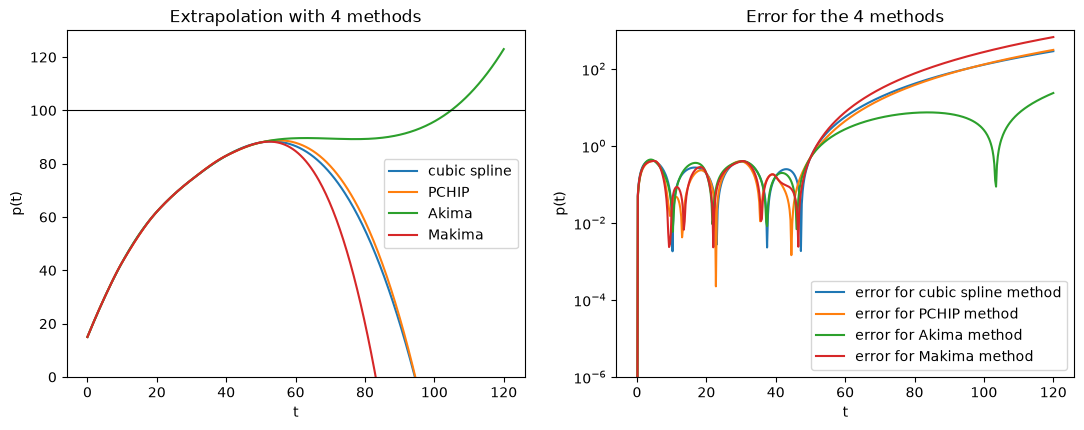

In [63]:
te = np.linspace(0, 120, 481)

fig, axs = plt.subplots(1, 2, figsize=(13, 4.5))
for name, p in zip(names, methods):
    axs[0].plot(te, p(te), label=name)
    axs[1].semilogy(te, np.abs(p(te)-battery_model(te))+1e-12, label = f"error for {name} method")
    print(f"interpolation method {name} at 90 minutes: {p(90)}")

axs[0].axhline(100, color="k", lw=0.8)
axs[0].set_ylim(0, 130)
axs[1].set_ylim(1e-6, 1e3)
axs[0].set_xlabel("t"); axs[0].set_ylabel("p(t)")
axs[1].set_xlabel("t"); axs[1].set_ylabel("p(t)")
axs[0].legend()
axs[1].legend()
axs[0].set_title("Extrapolation with 4 methods")
axs[1].set_title("Error for the 4 methods")


**Your answer for Q1(b):**

Cubic spline, PCHIP, and Makima all give impossible battery levels. 

### Question 2: When Does the Battery Reach 80 %? (25 points)

Many phones stop charging at **80 %** to protect the battery. Using the **model** from Question 1, the time $t^*$ when the battery reaches 80 % is the root of
$$
f(t) = B(t) - 80 = 20 - 85\,e^{-0.04\,t}, \qquad f'(t) = 3.4\,e^{-0.04\,t}.
$$
This one can also be solved by hand: $t^* = \ln(85/20)/0.04$. Use it to check your answers.

**(a) [13 pts] Bracketing methods.**
1. Define `f` and plot it on $[0, 120]$ with a horizontal line at $0$. Use the plot to choose a bracket $[a, b]$.
2. Find the root with `bisect`, `brentq` and `toms748`. For each method print the root, the number of iterations, and `converged`.
3. Print the exact $t^*$ and the error of the `brentq` root.

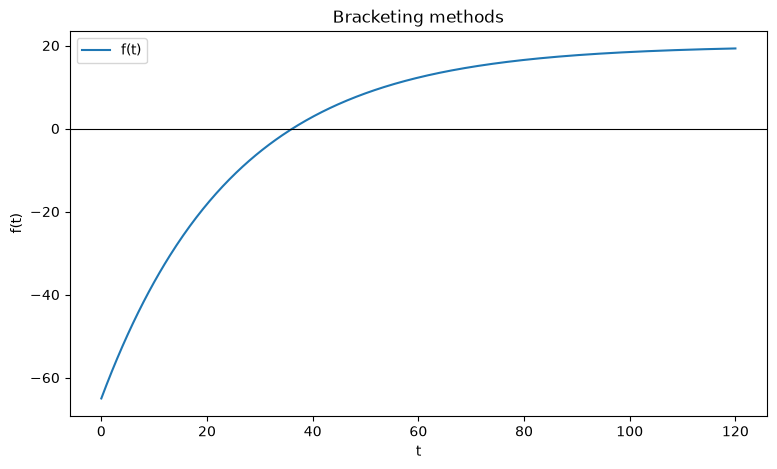

bisect   root = 36.172974573408965 iterations = 44 converged = True
exact t = 36.17297457340813 error = 0.0
brentq   root = 36.172974573408133 iterations =  7 converged = True
exact t = 36.17297457340813 error = 0.0
toms748  root = 36.172974573408140 iterations =  5 converged = True
exact t = 36.17297457340813 error = 0.0


In [61]:
f = lambda t: 20 - 85*np.exp(-0.04*t)
df = lambda t: 3.4*np.exp(-0.04*t)

fig, ax =plt.subplots(figsize=(9, 5))
ax.plot(te, f(te), label="f(t)")
ax.axhline(0, color="k", lw=0.8)  
ax.set_xlabel("t")
ax.set_ylabel("f(t)")
ax.legend()
ax.set_title("Bracketing methods")
plt.show()

t_star = np.log(85/20)/0.04
brentq = root_scalar(f, method="brentq", bracket=[20,40])

for m in ["bisect", "brentq", "toms748"]:
    sol = root_scalar(f, method=m, bracket=[20, 40])
    print(f"{m:8s} root = {sol.root:.15f} iterations = {sol.iterations:2d} converged = {sol.converged}")
    print(f"exact t = {t_star} error = {np.abs(t_star - brentq.root)}")



**(b) [12 pts] Newton's method and the starting point.**
Newton's method needs the derivative: pass it as `fprime=df`, where `df` is the derivative $f'(t)$ of the function `f`. Run `newton` from $t_0 = 10$ and from $t_0 = 120$, and print the root and the number of iterations for each.

In the markdown cell below: why does Newton need many more iterations from $t_0 = 120$? (*Hint:* compute the first Newton step $t_1 = t_0 - f(t_0)/f'(t_0)$ from $t_0 = 120$, or look at how flat $f$ is there.)

In [62]:
s_t10 = root_scalar(f, method="newton", x0=10, fprime=df)
s_t120 = root_scalar(f, method="newton", x0=120, fprime=df)
print(f"{s_t10.method:8s} root = {s_t10.root:.15f}   iterations = {s_t10.iterations} at t0 = 10")
print(f"{s_t120.method:8s} root = {s_t120.root:.15f}   iterations = {s_t120.iterations} at t0 = 120")


newton   root = 36.172974573408133   iterations = 6 at t0 = 10
newton   root = 36.172974573408140   iterations = 31 at t0 = 120


**Your answer for Q2(b):**

Because the slope is so flat df will be very small and since it is dividing f that will give a large number resulting in a large negative first step. Because of the first step it will take longer for the method to reach the root since it's overshot so far. 

### Bonus: Root Finding on the Measured Data (10 points)

In real life you do **not** know the model, only the seven measurements. Combine Questions 1 and 2: find the 80 % time from the **interpolants** instead.

1. For each of the four interpolants `p` from Q1(a), solve $p(t) - 80 = 0$ on the bracket $[30, 40]$ (the measurements pass 80 % between $t = 30$ and $t = 40$) with **three** methods: `brentq`, `ridder` and `toms748`. For each interpolant and method, print the root, the number of iterations, and the difference from the exact $t^*$ of Question 2.

In the markdown cell below, compare: for a given interpolant, do the three methods give the same root? Which method needs the fewest iterations? Which interpolant gives the best 80 % time?

In [7]:
# TODO: your code for the Bonus question here

**Your answer for the Bonus question:**

*(Same root for the three methods? Fewest iterations? Best interpolant?)*

### Submission Instructions

**Submit this assignment on Canvas only.** There is no GitHub submission for this assignment.

1. Before submitting, choose **Kernel → Restart & Run All** (or **Restart Kernel and Run All Cells**) and check that every cell runs without errors and that **all figures are visible** in the notebook. Figures that do not appear in the submitted notebook cannot be graded.
2. Make sure your written answers are filled in, in the markdown cells marked *Your answer*, and that the AI Usage Disclosure at the top is filled in.
3. Upload the completed `.ipynb` file to the Assignment IV page on Canvas.

No late submissions will be accepted.